# ECG Insight Lab: Project Story, Evolution & System Architecture

**Professor & Evaluator Teaching Demonstration Notebook**  
*CardioSense / ECG Insight Lab — Academic Exploration Platform*

> [!IMPORTANT]
> **Non-Clinical Research Disclaimer:**  
> This software is designed strictly for academic research and educational exploration. It is **not** a certified medical device and has not been approved for clinical diagnosis, patient triage, or healthcare decision-making. No physical patient sensors or embedded hardware (ESP32/AD8232) are connected or required.

---

## Learning Objectives
1. Understand the historical origin of the project and why legacy approaches to ECG digitization and classification failed.
2. Trace the step-by-step technical progression from Phase 0 (audit) through Phase 4 (productization).
3. Comprehend the core architectural principle: **Strict Gated Decoupling** between Workflow A (paper ECG image digitization) and Workflow B (digital waveform ML).
4. Review system health and artifact integrity via automated diagnostics.


In [1]:
# Cell 1: Environment Inspection & System Health Diagnostics
import sys
import platform
from pathlib import Path
import pandas as pd

# Verify workspace root
print(f"Python Runtime: {platform.python_version()} on {platform.system()} ({platform.machine()})")
print(f"Executable: {sys.executable}")

# Check system diagnostics from ecg_lab
from ecg_lab.diagnostics import check_system_diagnostics
diag = check_system_diagnostics()

diag_summary = []
for k, comp in diag.to_dict()["components"].items():
    diag_summary.append({
        "Component": comp["name"],
        "Status": comp["status_label"],
        "Available": "Yes" if comp["is_available"] else "No"
    })

pd.DataFrame(diag_summary)


Python Runtime: 3.14.4 on Linux (x86_64)
Executable: /run/media/op/DATA/Omkar/VIT/2y/3 sem/Project_expo/code/.venv/bin/python


,Component,Status,Available
0,PTB-XL Metadata,Present (Verified),Yes
1,WFDB Signal Completeness,"Complete (21,799 records)",Yes
2,Full-Fold Model Artifact,Verified (Cryptographic SHA-256 match),Yes
3,Phase 3.1 Pilot Model Archive,Archived (SHA-256 Verified),Yes
4,Paired Bootstrap Audit,Verified (Delta = +0.1510),Yes
5,Synthetic Demo Fixtures,Present (Verified),Yes
6,Privacy & Data Lifecycle Safeguards,Enforced (Zero-Persistence In-Memory Uploads),Yes


## 1. Project Background & Legacy Defect Analysis

### The Initial Concept
The original project concept (*CardioSense*) was conceived as a multi-modal cardiac assessment platform. It documented ambitious goals:
1. Optical extraction of 1D electrocardiogram signals from paper strips or photographs.
2. Automated diagnostic classification using machine learning.
3. Live real-time hardware telemetry utilizing an **AD8232 ECG sensor** paired with an **ESP32 microcontroller**.

> [!NOTE]
> **Owner-Editable Note on Hardware:**  
> The legacy project documentation and reports conceptualized a live sensor hardware subsystem. However, the audited implementation and the current repository are entirely **software-only research prototypes**. No live embedded sensors are attached, and all digital demonstrations utilize the public PhysioNet PTB-XL dataset.

---

### The Phase 0 Technical Audit Findings
In the Phase 0 audit (`docs/AUDIT_REPORT.md`), a senior technical audit revealed critical blockers in the legacy repository (dating to March 2025):
- **Dangerous Pickles:** Legacy `.pkl` files (e.g., `model.pkl`) contained insecure deserialization vulnerabilities and were trained on undocumented synthetic arrays.
- **Patient Leakage:** Legacy scripts performed record-level random splits, leaking waveforms from the same patient across train and test sets.
- **Unverified Paper-to-Digital Bridge:** Attempted to feed raw, uncalibrated image pixels directly into classification models without resolving grid calibration or domain shift.
- **Inflated Claims:** Unsubstantiated diagnostic accuracy claims were asserted without rigorous statistical bounds or peer-reviewed evaluation.


## 2. Chronological Phase-by-Phase Evolution

The project was rebuilt from the ground up through six rigorous engineering phases:

| Phase | Milestone | Core Achievement & Verification Evidence |
| :--- | :--- | :--- |
| **Phase 0** | Technical Audit | Quarantined legacy pickle files (`legacy/`); established security, privacy, and evaluation requirements. |
| **Phase 1** | Foundation & Security | Clean environment, editorial design tokens, and robust image validation with decompression bomb guards (`ecg_lab/validation.py`). |
| **Phase 2** | Image Digitization | Classical morphological centroid digitizer (`ClassicalBaselineDigitizer`); synthetic 12-lead benchmark ($r=0.6932$, $\text{MAE}=0.0725$); honest relative coordinates. |
| **Phase 3** | Waveform ML Pipeline | Official PTB-XL v1.0.3 dataset (21,799 records); zero-leakage patient-separated folds; SCP-ECG 5 superclasses; 148 deterministic signal features. |
| **Phase 3.1** | Evaluation Audit | Corrected label mapping; audited baseline; established full Fold 10 benchmark ($N=2,198$). |
| **Phase 3.2** | Full-Fold Training | Scaled training to all 17,418 records (Folds 1–8); tuned decision thresholds on all 2,183 records (Fold 9); achieved **0.6093 Macro F1** on Fold 10. |
| **Phase 3.2.1** | Paired Model Comparison | Matched patient-cluster bootstrap ($B=2,000$); proved statistically significant gain ($\Delta = +0.1510$, 95% CI $[0.1343, 0.1681]$); 0/2,000 replicates non-positive. |
| **Phase 4** | Productization & Privacy | Quiet Academic Editorial UI (`app.py`); zero-persistence in-memory upload privacy; 7-point automated diagnostics; 64 automated tests. |
| **Phase 5** | Teaching Layer | 4 interactive notebooks; formal repository schema; portfolio README with authentic scientific figures. |


## 3. Core Architectural Principle: Decoupled Workflows

A central contribution of this project is the **deliberate architectural separation** between Workflow A and Workflow B:

```text
+-------------------------------------------------------------------------------------------------+
|                                 ECG INSIGHT LAB ARCHITECTURE                                    |
+-------------------------------------------------------------------------------------------------+
|                                                                                                 |
|   [WORKFLOW A: ECG IMAGE LAB]                          [WORKFLOW B: WAVEFORM ML LAB]            |
|   Paper ECG Ingestion & Optical Recovery               PhysioNet PTB-XL Digital Waveform ML      |
|                                                                                                 |
|   +-----------------------+                            +--------------------------------+       |
|   | Paper ECG Image / Scan|                            | PhysioNet PTB-XL v1.0.3        |       |
|   +-----------+-----------+                            | 21,799 12-Lead Records (100 Hz)|       |
|               |                                        +---------------+----------------+       |
|               v                                                        |                        |
|   +-----------------------+                                            v                        |
|   | Image Validation Gate |                            +--------------------------------+       |
|   | (Format, Size, Dim)   |                            | Patient-Separated Splits       |       |
|   +-----------+-----------+                            | (Folds 1-8 / Fold 9 / Fold 10) |       |
|               |                                        +---------------+----------------+       |
|               v                                                        |                        |
|   +-----------------------+                                            v                        |
|   | 12-Lead Segmentation  |                            +--------------------------------+       |
|   | (3x4 Clinical Bounding)                            | 148 Deterministic Features     |       |
|   +-----------+-----------+                            +---------------+----------------+       |
|               |                                                        |                        |
|               v                                                        v                        |
|   +-----------------------+                            +--------------------------------+       |
|   | Classical Morphological|                           | Multi-Label Diagnostic Model   |       |
|   | Centroid Digitizer    |                            | (OvR Logistic Regression)      |       |
|   +-----------+-----------+                            +---------------+----------------+       |
|               |                                                        |                        |
|               v                                                        v                        |
|   +-----------------------+                            +--------------------------------+       |
|   | 1D Waveform Recovery  |                            | Held-Out Evaluation (Fold 10)  |       |
|   | (Relative Coordinates)|                            | (Macro F1 = 0.6093, N=2,198)   |       |
|   | CSV / JSON Export     |                            +--------------------------------+       |
|   +-----------+-----------+                                                                     |
|               |                                                                                 |
|               X <=========== GATED SEPARATION (STRICTLY PROHIBITED) =============>              |
|                              No Paper-to-Digital Classification Bridge                          |
+-------------------------------------------------------------------------------------------------+
```


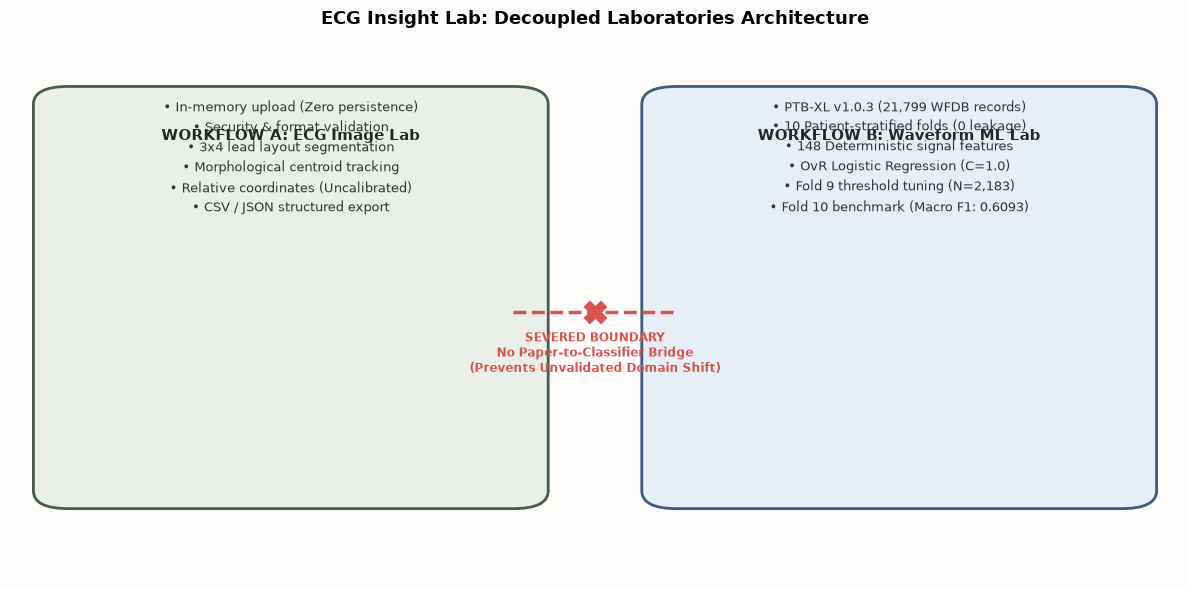

In [2]:
# Cell 2: Visualizing the Decoupled System Architecture
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(12, 6), facecolor="#FDFCFB")
ax.set_facecolor("#FDFCFB")

# Workflow A Box
box_a = patches.FancyBboxPatch((0.05, 0.25), 0.38, 0.65, boxstyle="round,pad=0.03", fc="#EAEFEA", ec="#455D4A", lw=2)
ax.add_patch(box_a)
ax.text(0.24, 0.84, "WORKFLOW A: ECG Image Lab", fontsize=11, fontweight="bold", ha="center", color="#252722")
ax.text(0.24, 0.72, "• In-memory upload (Zero persistence)\n• Security & format validation\n• 3x4 lead layout segmentation\n• Morphological centroid tracking\n• Relative coordinates (Uncalibrated)\n• CSV / JSON structured export", fontsize=9, ha="center", color="#333333", linespacing=1.6)

# Workflow B Box
box_b = patches.FancyBboxPatch((0.57, 0.25), 0.38, 0.65, boxstyle="round,pad=0.03", fc="#E8EEF5", ec="#3D5A80", lw=2)
ax.add_patch(box_b)
ax.text(0.76, 0.84, "WORKFLOW B: Waveform ML Lab", fontsize=11, fontweight="bold", ha="center", color="#252722")
ax.text(0.76, 0.72, "• PTB-XL v1.0.3 (21,799 WFDB records)\n• 10 Patient-stratified folds (0 leakage)\n• 148 Deterministic signal features\n• OvR Logistic Regression (C=1.0)\n• Fold 9 threshold tuning (N=2,183)\n• Fold 10 benchmark (Macro F1: 0.6093)", fontsize=9, ha="center", color="#333333", linespacing=1.6)

# Severed / Gated Boundary
ax.plot([0.43, 0.57], [0.55, 0.55], color="#D9534F", linestyle="--", lw=2.5)
ax.scatter([0.50], [0.55], color="#D9534F", s=250, zorder=5, marker="X")
ax.text(0.50, 0.45, "SEVERED BOUNDARY\nNo Paper-to-Classifier Bridge\n(Prevents Unvalidated Domain Shift)", fontsize=8.5, fontweight="bold", ha="center", color="#D9534F")

ax.set_xlim(0, 1)
ax.set_ylim(0.1, 1.0)
ax.axis("off")
plt.title("ECG Insight Lab: Decoupled Laboratories Architecture", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()


## 4. Current Limitations & Defense Talking Points

When presenting this work to an academic committee or professor, the following technical nuances are essential:

### Question 1: Why not feed the digitized paper ECG directly into the PTB-XL classifier?
**Answer:** The digitized waveforms from Workflow A exist in **uncalibrated relative pixel coordinates**. The PTB-XL classifier is trained on **calibrated physical units** (millivolts sampled at 100 Hz). Passing uncalibrated optical extractions directly into the classifier introduces severe, uncontrolled domain shift, leading to spurious, scientifically invalid predictions. A bridge requires paired optical-digital datasets and formal domain adaptation.

### Question 2: Why choose Logistic Regression over a Deep Convolutional ResNet?
**Answer:** In academic and clinical settings, baseline models must be reproducible, fast to train on commodity hardware, and explainable. The One-vs-Rest Logistic Regression baseline trains in seconds on 148 deterministic physiological features, uses only 515 MiB peak RAM, and achieves a solid 0.6093 Macro F1 across 2,198 test records with zero patient leakage.

---

## 5. Summary & Next Steps
- Continue to **[Lab 1: ECG Image Digitization](01_ECG_Image_Digitization.ipynb)** to explore optical signal recovery on synthetic benchmarks.
- Explore **[Lab 2: PTB-XL Data & Features](02_PTBXL_Data_and_Features.ipynb)** to examine physiological signal features and patient stratification.
- Inspect **[Lab 3: Model Predictions & Evaluation](03_Model_Predictions_and_Evaluation.ipynb)** to verify multi-label metrics and paired bootstrap confidence intervals.
